<a href="https://colab.research.google.com/github/ritupatell2007-debug/TruthLens-AI/blob/main/Copy_of_TruthLens_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Step 1.1: Import the libraries we need
import pandas as pd            # tables of data (like Excel inside Python)
import numpy as np             # fast math on numbers
import re                      # find/replace text patterns (for cleaning)
import string                  # list of punctuation characters
import nltk                    # natural language toolkit (stopwords)
import matplotlib.pyplot as plt  # graphs
import sklearn                 # machine learning library

nltk.download('stopwords')     # download the list of common English words

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("Setup complete ✅")

pandas: 2.2.3
numpy: 2.4.6
scikit-learn: 1.6.1
Setup complete ✅


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
# Step 1.2: Upload the dataset from your computer
from google.colab import files
uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))

Saving WELFake_Dataset.csv.zip to WELFake_Dataset.csv.zip
Uploaded files: ['WELFake_Dataset.csv.zip']


In [ ]:
# Step 1.3: Unzip (if you uploaded a zip) and load the CSV
import glob, zipfile

# If a zip file was uploaded, extract it
for z in glob.glob("*.zip"):
    with zipfile.ZipFile(z) as zf:
        zf.extractall(".")
        print("Extracted:", z)

# Find the dataset file
csv_files = [f for f in glob.glob("*.csv") if "WELFake" in f]
print("Dataset file found:", csv_files)

# Load it into a DataFrame (a table)
df = pd.read_csv(csv_files[0])

print("\nShape (rows, columns):", df.shape)
print("\nColumn names:", list(df.columns))
print("\nFirst 5 rows:")
df.head()

Extracted: WELFake_Dataset.csv.zip
Dataset file found: ['WELFake_Dataset.csv']

Shape (rows, columns): (72134, 4)

Column names: ['Unnamed: 0', 'title', 'text', 'label']

First 5 rows:


,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [ ]:
# Step 1.4: Basic inspection
print("Data types and non-null counts:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nLabel distribution (how many of each class):")
print(df['label'].value_counts())

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  72134 non-null  int64 
 1   title       71576 non-null  object
 2   text        72095 non-null  object
 3   label       72134 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 2.2+ MB

Missing values per column:
Unnamed: 0      0
title         558
text           39
label           0
dtype: int64

Number of duplicate rows: 0

Label distribution (how many of each class):
label
1    37106
0    35028
Name: count, dtype: int64


In [ ]:
# Step 1.5: Read random samples from each label to decide what 0 and 1 mean
pd.set_option('display.max_colwidth', None)

# Only use rows that have both a title and text, so the samples are readable
sample_df = df.dropna(subset=['title', 'text'])

for lab in [0, 1]:
    print("=" * 70)
    print(f"LABEL = {lab}   (5 random examples)")
    print("=" * 70)
    samples = sample_df[sample_df['label'] == lab].sample(5, random_state=42)
    for i, (_, row) in enumerate(samples.iterrows(), start=1):
        print(f"\n[{i}] TITLE: {row['title']}")
        print(f"    TEXT : {row['text'][:300]}...")

LABEL = 0   (5 random examples)

[1] TITLE: Two People Die after Eating Raw-Milk Cheese Made in New York State - The New York Times
    TEXT : Two people have died following an outbreak of listeria linked to a popular artisanal raw milk cheese made in upstate New York, the authorities said this week. The deaths occurred in Vermont and Connecticut, local officials said. Four other people in New York and Florida reported feeling sick after e...

[2] TITLE: DUP blames Sinn Fein for Northern Ireland talks collapse
    TEXT : BELFAST (Reuters) - A senior member of Northern Ireland s Democratic Unionist Party on Wednesday blamed rivals Sinn Fein for the collapse of talks on forming a power-sharing government and suggested the DUP would not compromise on the key issue of the Irish language.  In the first public statement f...

[3] TITLE: Exclusive: Former top Brazil prosecutor says successor, police chief slowing graft probes
    TEXT : BRASILIA (Reuters) - Three senior Brazilian law enforcem

In [ ]:
# Step 1.6: Proper duplicate check (ignore the row-number column)
dups_full = df.duplicated(subset=['title', 'text']).sum()
dups_text = df.duplicated(subset=['text']).sum()

print("Duplicate rows (same title AND text):", dups_full)
print("Duplicate rows (same text only):", dups_text)

# Do any duplicated texts have CONFLICTING labels? (same article marked both real and fake)
grp = df.dropna(subset=['text']).groupby('text')['label'].nunique()
print("Texts that appear with both labels:", (grp > 1).sum())

Duplicate rows (same title AND text): 8456
Duplicate rows (same text only): 9415
Texts that appear with both labels: 1


In [ ]:
# Step 1.5 + 1.6: Check what the labels mean, and check for duplicates

# ---------- Part A: duplicates (ignore the row-number column) ----------
dups_full = df.duplicated(subset=['title', 'text']).sum()
dups_text = df.duplicated(subset=['text']).sum()
print("Duplicate rows (same title AND text):", dups_full)
print("Duplicate rows (same text only):", dups_text)

grp = df.dropna(subset=['text']).groupby('text')['label'].nunique()
print("Texts that appear with both labels:", (grp > 1).sum())

# ---------- Part B: read samples from each label ----------
sample_df = df.dropna(subset=['title', 'text'])

for lab in [0, 1]:
    print("\n" + "=" * 70)
    print(f"LABEL = {lab}   (5 random examples)")
    print("=" * 70)
    samples = sample_df[sample_df['label'] == lab].sample(5, random_state=42)
    for i, (_, row) in enumerate(samples.iterrows(), start=1):
        print(f"\n[{i}] TITLE: {row['title']}")
        print(f"    TEXT : {row['text'][:300]}...")

Duplicate rows (same title AND text): 8456
Duplicate rows (same text only): 9415
Texts that appear with both labels: 1

LABEL = 0   (5 random examples)

[1] TITLE: Two People Die after Eating Raw-Milk Cheese Made in New York State - The New York Times
    TEXT : Two people have died following an outbreak of listeria linked to a popular artisanal raw milk cheese made in upstate New York, the authorities said this week. The deaths occurred in Vermont and Connecticut, local officials said. Four other people in New York and Florida reported feeling sick after e...

[2] TITLE: DUP blames Sinn Fein for Northern Ireland talks collapse
    TEXT : BELFAST (Reuters) - A senior member of Northern Ireland s Democratic Unionist Party on Wednesday blamed rivals Sinn Fein for the collapse of talks on forming a power-sharing government and suggested the DUP would not compromise on the key issue of the Irish language.  In the first public statement f...

[3] TITLE: Exclusive: Former top Brazil prosecut

Rows at start: 72134
Removed rows with no content: 0
Removed contradictory-label rows: 0
Removed duplicate rows: 8458

Rows after cleaning: 63676

Class counts:
label_name
REAL    34790
FAKE    28886
Name: count, dtype: int64

Class percentages:
label_name
REAL    54.6
FAKE    45.4
Name: proportion, dtype: float64


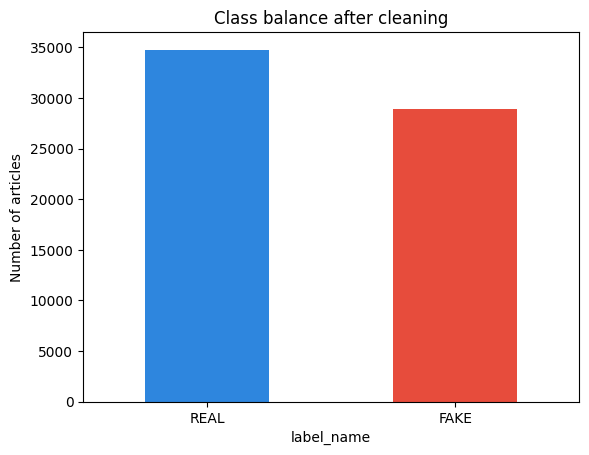


Saved clean_data.csv ✅


,title,label_name
0,LAW ENFORCEMENT ON HIGH ALERT Following Threats Against Cops And Whites On 9-11By #BlackLivesMatter And #FYF911 Terrorists [VIDEO],FAKE
1,,FAKE
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MOST CHARLOTTE RIOTERS WERE “PEACEFUL” PROTESTERS…In Her Home State Of North Carolina [VIDEO],FAKE
3,"Bobby Jindal, raised Hindu, uses story of Christian conversion to woo evangelicals for potential 2016 bid",REAL
4,SATAN 2: Russia unvelis an image of its terrifying new ‘SUPERNUKE’ – Western world takes notice,FAKE


In [ ]:
# Step 2: Clean the dataset (missing values, duplicates, labels)

print("Rows at start:", len(df))

# 1) Drop the useless row-number column
data = df.drop(columns=['Unnamed: 0']).copy()

# 2) Missing values: replace empty title/text with an empty string
data['title'] = data['title'].fillna('')
data['text'] = data['text'].fillna('')

# 3) Combine headline + article into ONE column the model will read
data['content'] = (data['title'] + ' ' + data['text']).str.strip()

# 4) Remove rows that have no content at all
before = len(data)
data = data[data['content'] != '']
print("Removed rows with no content:", before - len(data))

# 5) Remove articles that appear with BOTH labels (contradictory)
label_count = data.groupby('content')['label'].transform('nunique')
before = len(data)
data = data[label_count == 1]
print("Removed contradictory-label rows:", before - len(data))

# 6) Remove duplicate articles (keep the first copy)
before = len(data)
data = data.drop_duplicates(subset='content', keep='first')
print("Removed duplicate rows:", before - len(data))

# 7) Give labels readable names (we verified: 0 = REAL, 1 = FAKE)
data['label_name'] = data['label'].map({0: 'REAL', 1: 'FAKE'})

data = data.reset_index(drop=True)
print("\nRows after cleaning:", len(data))
print("\nClass counts:")
print(data['label_name'].value_counts())
print("\nClass percentages:")
print((data['label_name'].value_counts(normalize=True) * 100).round(1))

# 8) Quick bar chart of the classes
data['label_name'].value_counts().plot(kind='bar', color=['#2e86de', '#e74c3c'])
plt.title("Class balance after cleaning")
plt.ylabel("Number of articles")
plt.xticks(rotation=0)
plt.show()

# 9) Save the cleaned data so we don't have to repeat this
data.to_csv("clean_data.csv", index=False)
print("\nSaved clean_data.csv ✅")
data[['title', 'label_name']].head()

In [ ]:
# Step 3: Text preprocessing
import re
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords', quiet=True)

# ---------- Part A: Check the "Reuters shortcut" ----------
has_reuters = data['content'].str.lower().str.contains('reuters', regex=False)
summary = has_reuters.groupby(data['label_name']).agg(['sum', 'mean'])
summary['mean'] = (summary['mean'] * 100).round(1)
summary.columns = ['articles mentioning "reuters"', '% of that class']
print("How often does the word 'reuters' appear in each class?")
print(summary)

# ---------- Part B: The cleaning function ----------
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = text.lower()                              # 1. lowercase
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)  # 2. remove URLs
    text = re.sub(r'<.*?>', ' ', text)               # 3. remove HTML tags
    text = re.sub(r'\breuters\b', ' ', text)         # 4. remove the source name (avoid shortcut)
    text = re.sub(r'[^a-z\s]', ' ', text)            # 5. remove punctuation, digits, symbols
    words = text.split()                             # 6. split into words (also fixes extra spaces)
    words = [w for w in words if w not in stop_words and len(w) > 1]  # 7. stopwords + 1-letter junk
    return ' '.join(words)                           # 8. join back into a clean string

# ---------- Part C: Before / after example ----------
example = data.loc[3, 'content']
print("\n--- BEFORE (first 300 characters) ---")
print(example[:300])
print("\n--- AFTER (first 300 characters) ---")
print(clean_text(example)[:300])

# ---------- Part D: Apply to every article ----------
data['clean_text'] = data['content'].apply(clean_text)

# Remove articles that became empty after cleaning
before = len(data)
data = data[data['clean_text'].str.strip() != ''].reset_index(drop=True)
print("\nRemoved articles empty after cleaning:", before - len(data))

# ---------- Part E: Check the result ----------
data['word_count'] = data['clean_text'].str.split().str.len()
print("\nWords per cleaned article:")
print(data.groupby('label_name')['word_count'].describe().round(0))
print("\nArticles with fewer than 10 words:", (data['word_count'] < 10).sum())

data.to_csv("clean_data.csv", index=False)
print("\nRows ready for modelling:", len(data))
print("Saved clean_data.csv ✅")

How often does the word 'reuters' appear in each class?
            articles mentioning "reuters"  % of that class
label_name                                                
FAKE                                  490              1.7
REAL                                21423             61.6

--- BEFORE (first 300 characters) ---
Bobby Jindal, raised Hindu, uses story of Christian conversion to woo evangelicals for potential 2016 bid A dozen politically active pastors came here for a private dinner Friday night to hear a conversion story unique in the context of presidential politics: how Louisiana Gov. Bobby Jindal traveled

--- AFTER (first 300 characters) ---
bobby jindal raised hindu uses story christian conversion woo evangelicals potential bid dozen politically active pastors came private dinner friday night hear conversion story unique context presidential politics louisiana gov bobby jindal traveled hinduism protestant christianity ultimately became

Removed articles empty after

In [ ]:
# Step 4: Train/test split + TF-IDF
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
import joblib

# ---------- Part A: Define inputs (X) and answers (y) ----------
X = data['clean_text']                         # the text the model reads
y = (data['label_name'] == 'FAKE').astype(int) # 1 = FAKE, 0 = REAL

# ---------- Part B: Split 80% train / 20% test ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20% hidden for the final exam
    random_state=42,     # same split every time
    stratify=y           # keep the REAL/FAKE ratio equal in both sets
)

print("Training articles:", len(X_train))
print("Testing articles :", len(X_test))
print("\nFAKE % in train:", round(y_train.mean() * 100, 1))
print("FAKE % in test :", round(y_test.mean() * 100, 1))

# ---------- Part C: TF-IDF ----------
tfidf = TfidfVectorizer(
    max_features=50000,   # keep the 50,000 most useful words
    min_df=5,             # ignore words appearing in fewer than 5 articles (typos, rare names)
    max_df=0.7,           # ignore words in more than 70% of articles (too common to help)
    sublinear_tf=True     # dampen the effect of a word repeated many times
)

X_train_tfidf = tfidf.fit_transform(X_train)   # learn vocabulary from TRAIN only
X_test_tfidf = tfidf.transform(X_test)         # apply it to TEST (no learning)

print("\nTF-IDF matrix (train):", X_train_tfidf.shape, "= (articles, words)")
print("TF-IDF matrix (test) :", X_test_tfidf.shape)

density = X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1])
print("Share of cells that are non-zero:", round(density * 100, 2), "%")

# ---------- Part D: Peek at the vocabulary ----------
vocab = tfidf.get_feature_names_out()
print("\nTotal words in vocabulary:", len(vocab))
print("Sample words:", list(vocab[:15]), "...", list(vocab[-5:]))

# ---------- Part E: Save our work so far ----------
joblib.dump((X_train, X_test, y_train, y_test), "split_data.joblib")
joblib.dump(tfidf, "tfidf_vectorizer.joblib")
print("\nSaved split_data.joblib and tfidf_vectorizer.joblib ✅")

Training articles: 50898
Testing articles : 12725

FAKE % in train: 45.3
FAKE % in test : 45.3

TF-IDF matrix (train): (50898, 50000) = (articles, words)
TF-IDF matrix (test) : (12725, 50000)
Share of cells that are non-zero: 0.4 %

Total words in vocabulary: 50000
Sample words: ['aa', 'aaa', 'aab', 'aal', 'aap', 'aapl', 'aaron', 'aaronkleinshow', 'aarp', 'ab', 'aba', 'abaaoud', 'ababa', 'aback', 'abad'] ... ['zwick', 'zwischen', 'zy', 'zyuganov', 'zz']

Saved split_data.joblib and tfidf_vectorizer.joblib ✅


In [ ]:
# Step 5: Train and compare three models
import time
import warnings
import joblib
import pandas as pd
from sklearn.linear_model import LogisticRegression, PassiveAggressiveClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Newer scikit-learn versions may print a harmless deprecation notice for
# PassiveAggressiveClassifier. The model still works, so we hide the notice.
warnings.filterwarnings("ignore", category=FutureWarning)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Naive Bayes": MultinomialNB(),
    "Passive Aggressive": PassiveAggressiveClassifier(max_iter=1000, random_state=42),
}

results = []
trained_models = {}
test_predictions = {}

for name, model in models.items():
    start = time.time()
    print(f"Training {name} ...")

    # 5-fold cross-validation on TRAINING data only (used to pick the winner)
    cv_f1 = cross_val_score(model, X_train_tfidf, y_train, cv=5, scoring="f1").mean()

    # Train on the full training set, then take the final exam on the test set
    model.fit(X_train_tfidf, y_train)
    pred = model.predict(X_test_tfidf)

    trained_models[name] = model
    test_predictions[name] = pred

    results.append({
        "Model": name,
        "CV F1 (train)": round(cv_f1, 4),
        "Accuracy": round(accuracy_score(y_test, pred), 4),
        "Precision": round(precision_score(y_test, pred), 4),
        "Recall": round(recall_score(y_test, pred), 4),
        "F1-score": round(f1_score(y_test, pred), 4),
        "Seconds": round(time.time() - start, 1),
    })

results_df = pd.DataFrame(results).set_index("Model")
print("\n===== RESULTS (FAKE = positive class) =====")
print(results_df.to_string())

# Pick the winner using cross-validation F1 (not the test set)
best_name = results_df["CV F1 (train)"].idxmax()
print("\nBest model by cross-validation F1:", best_name)

# Save everything for the next steps
joblib.dump(trained_models, "all_models.joblib")
joblib.dump(test_predictions, "test_predictions.joblib")
results_df.to_csv("model_comparison.csv")
print("Saved all_models.joblib, test_predictions.joblib, model_comparison.csv ✅")

Training Logistic Regression ...
Training Naive Bayes ...
Training Passive Aggressive ...

===== RESULTS (FAKE = positive class) =====
                     CV F1 (train)  Accuracy  Precision  Recall  F1-score  Seconds
Model                                                                             
Logistic Regression         0.9462    0.9516     0.9524  0.9402    0.9462      9.0
Naive Bayes                 0.8542    0.8639     0.8587  0.8375    0.8480      0.5
Passive Aggressive          0.9502    0.9552     0.9500  0.9513    0.9506      3.7

Best model by cross-validation F1: Passive Aggressive
Saved all_models.joblib, test_predictions.joblib, model_comparison.csv ✅


Logistic Regression
              precision    recall  f1-score   support

        REAL     0.9509    0.9611    0.9560      6958
        FAKE     0.9524    0.9402    0.9462      5767

    accuracy                         0.9516     12725
   macro avg     0.9517    0.9506    0.9511     12725
weighted avg     0.9516    0.9516    0.9516     12725

Naive Bayes
              precision    recall  f1-score   support

        REAL     0.8680    0.8857    0.8768      6958
        FAKE     0.8587    0.8375    0.8480      5767

    accuracy                         0.8639     12725
   macro avg     0.8633    0.8616    0.8624     12725
weighted avg     0.8638    0.8639    0.8637     12725

Passive Aggressive
              precision    recall  f1-score   support

        REAL     0.9596    0.9585    0.9590      6958
        FAKE     0.9500    0.9513    0.9506      5767

    accuracy                         0.9552     12725
   macro avg     0.9548    0.9549    0.9548     12725
weighted avg     0.9552

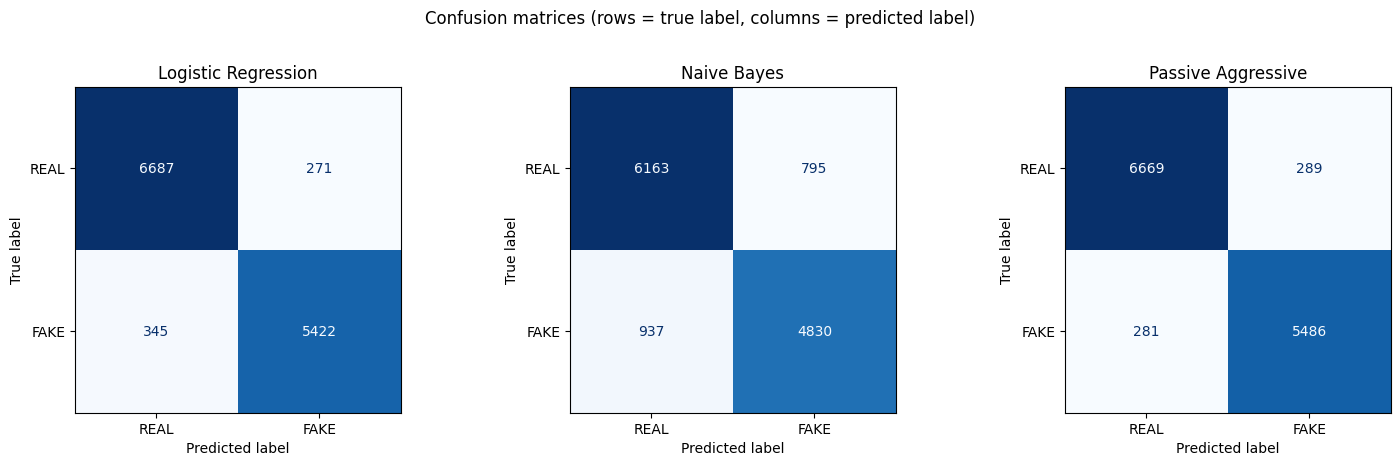


Mistake summary on the test set:
Logistic Regression    REAL called FAKE:  271 | FAKE called REAL:  345 | total wrong: 616
Naive Bayes            REAL called FAKE:  795 | FAKE called REAL:  937 | total wrong: 1732
Passive Aggressive     REAL called FAKE:  289 | FAKE called REAL:  281 | total wrong: 570


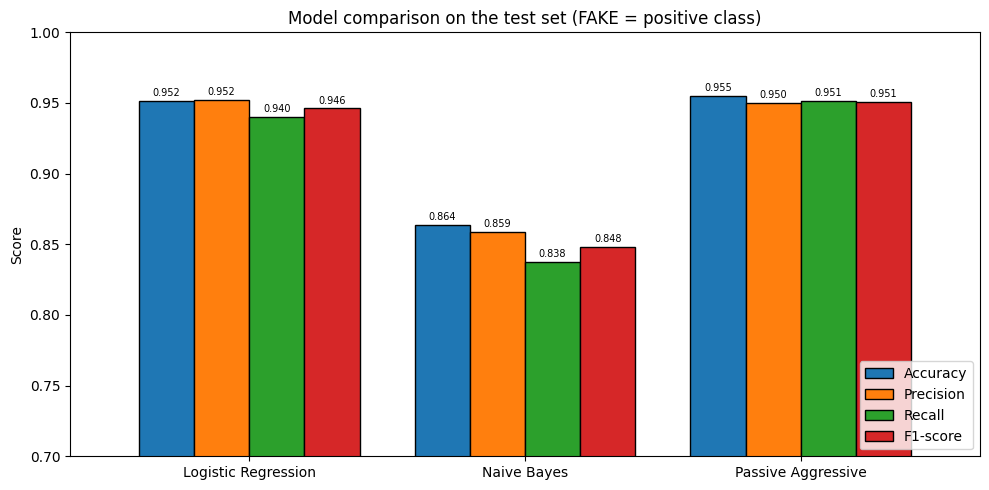


Saved confusion_matrices.png and model_comparison.png ✅


In [ ]:
# Step 6: Full evaluation with graphs
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

class_names = ["REAL", "FAKE"]

# ---------- Part A: Classification report for each model ----------
for name, pred in test_predictions.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, pred, target_names=class_names, digits=4))

# ---------- Part B: Confusion matrices side by side ----------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, pred) in zip(axes, test_predictions.items()):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(name)
plt.suptitle("Confusion matrices (rows = true label, columns = predicted label)", y=1.02)
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------- Part C: Plain-English mistake counts ----------
print("\nMistake summary on the test set:")
for name, pred in test_predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{name:22s} REAL called FAKE: {fp:4d} | FAKE called REAL: {fn:4d} | total wrong: {fp+fn}")

# ---------- Part D: Model comparison bar chart ----------
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
plot_df = results_df[metrics]

ax = plot_df.plot(kind="bar", figsize=(10, 5), width=0.8, edgecolor="black")
ax.set_ylim(0.7, 1.0)
ax.set_ylabel("Score")
ax.set_title("Model comparison on the test set (FAKE = positive class)")
ax.set_xlabel("")
plt.xticks(rotation=0)
ax.legend(loc="lower right")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=7, padding=2)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()

print("\nSaved confusion_matrices.png and model_comparison.png ✅")

Top 25 words pushing towards REAL:
['breitbart', 'https', 'washington', 'twitter', 'thursday', 'tuesday', 'follow', 'wednesday', 'monday', 'friday', 'york', 'sunday', 'factbox', 'jeromeehudson', 'dznussbaum', 'saturday', 'jerome', 'delingpole', 'ly', 'siriusxm', 'nussbaum', 'statement', 'cbn', 'berlin', 'ms']

Top 25 words pushing towards FAKE:
['via', 'featured', 'getty', 'image', 'video', 'read', 'october', 'breaking', 'hillary', 'nyp', 'wire', 'com', 'november', 'snip', 'flickr', 'nyt', 'wfb', 'us', 'bake', 'loading', 'photo', 'sputnik', 'wt', 'print', 'rino']


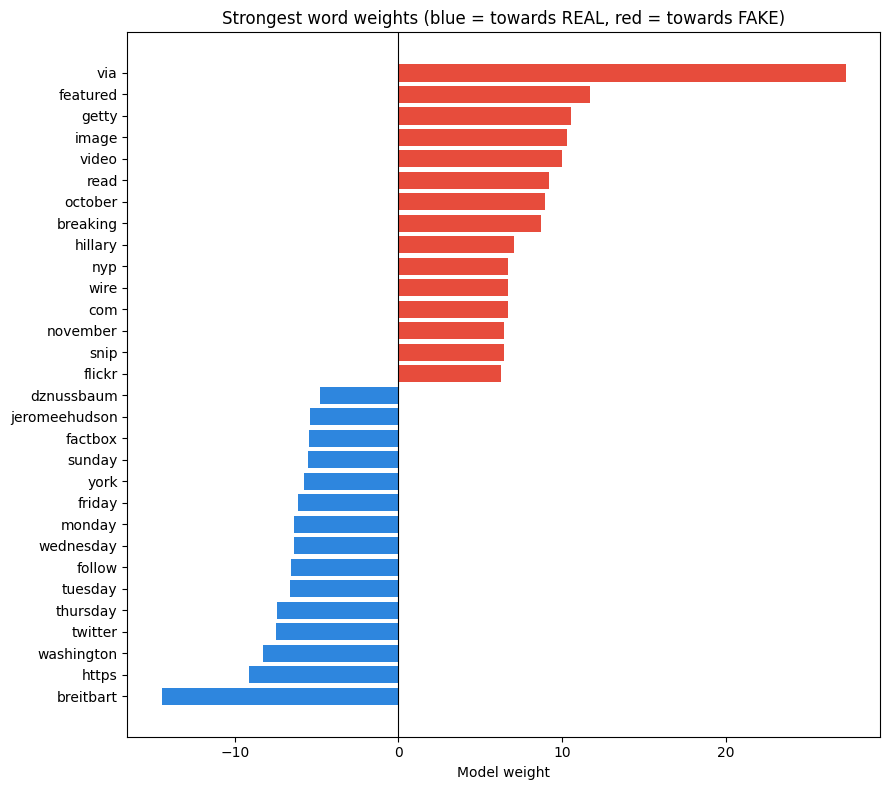


===== HEADLINE-ONLY TEST (Passive Aggressive) =====
Headlines tested: 12590
Accuracy : 0.7578
Precision: 0.6668
Recall   : 0.9169
F1-score : 0.7721

For comparison, full-article F1 was 0.9506


In [ ]:
# Step 7: Look inside the best model + test on headlines only

# ---------- Part A: Words with the strongest weights ----------
best_model = trained_models["Passive Aggressive"]
vocab = tfidf.get_feature_names_out()
coefs = best_model.coef_[0]          # positive weight = pushes towards FAKE

order = np.argsort(coefs)
top_real = list(vocab[order[:25]])               # most negative = REAL
top_fake = list(vocab[order[-25:][::-1]])        # most positive = FAKE

print("Top 25 words pushing towards REAL:")
print(top_real)
print("\nTop 25 words pushing towards FAKE:")
print(top_fake)

# Bar chart: top 15 each direction
n = 15
words = list(vocab[order[:n]]) + list(vocab[order[-n:]])
weights = list(coefs[order[:n]]) + list(coefs[order[-n:]])
colors = ["#2e86de"] * n + ["#e74c3c"] * n

plt.figure(figsize=(9, 8))
plt.barh(words, weights, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Strongest word weights (blue = towards REAL, red = towards FAKE)")
plt.xlabel("Model weight")
plt.tight_layout()
plt.savefig("top_words.png", dpi=150)
plt.show()

# ---------- Part B: Headline-only test ----------
# Use the titles of the TEST articles (the model never saw these articles)
t = data.loc[X_test.index, ['title', 'label']].copy()
t = t[t['title'].str.strip() != '']
t['clean_title'] = t['title'].apply(clean_text)
t = t[t['clean_title'].str.strip() != '']

Xt = tfidf.transform(t['clean_title'])
pred_t = best_model.predict(Xt)

print("\n===== HEADLINE-ONLY TEST (Passive Aggressive) =====")
print("Headlines tested:", len(t))
print("Accuracy :", round(accuracy_score(t['label'], pred_t), 4))
print("Precision:", round(precision_score(t['label'], pred_t), 4))
print("Recall   :", round(recall_score(t['label'], pred_t), 4))
print("F1-score :", round(f1_score(t['label'], pred_t), 4))
print("\nFor comparison, full-article F1 was", results_df.loc["Passive Aggressive", "F1-score"])

In [ ]:
# Step 8: (A) fingerprint-removal test, (B) headline-specific model
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
from sklearn.model_selection import cross_val_score

# ================= Part A: remove fingerprint words =================
fingerprint_words = sorted(set(top_real + top_fake))
print("Fingerprint words removed:", len(fingerprint_words))

tfidf_nf = TfidfVectorizer(max_features=50000, min_df=5, max_df=0.7,
                           sublinear_tf=True, stop_words=fingerprint_words)
Xtr_nf = tfidf_nf.fit_transform(X_train)
Xte_nf = tfidf_nf.transform(X_test)

pa_nf = PassiveAggressiveClassifier(max_iter=1000, random_state=42).fit(Xtr_nf, y_train)
pred_nf = pa_nf.predict(Xte_nf)

print("\n===== ARTICLE MODEL: before vs after removing fingerprint words =====")
print("F1 before:", results_df.loc["Passive Aggressive", "F1-score"])
print("F1 after :", round(f1_score(y_test, pred_nf), 4))
print("Accuracy after:", round(accuracy_score(y_test, pred_nf), 4))

# ================= Part B: headline-specific model =================
h = data[['title', 'label']].copy()
h['clean_title'] = h['title'].apply(clean_text)
h = h[h['clean_title'].str.split().str.len() >= 3]          # keep headlines with 3+ words

# remove repeated and contradictory headlines (prevents test-set leakage)
conflict = h.groupby('clean_title')['label'].transform('nunique')
h = h[conflict == 1].drop_duplicates(subset='clean_title').reset_index(drop=True)
print("\nHeadlines available:", len(h))
print("FAKE % :", round(h['label'].mean() * 100, 1))

Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    h['clean_title'], h['label'], test_size=0.2, random_state=42, stratify=h['label'])

tfidf_h = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)
Xh_train_t = tfidf_h.fit_transform(Xh_train)
Xh_test_t = tfidf_h.transform(Xh_test)
print("Headline TF-IDF shape (train):", Xh_train_t.shape)

h_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Naive Bayes": MultinomialNB(),
    "Passive Aggressive": PassiveAggressiveClassifier(max_iter=1000, random_state=42),
}

rows, h_trained = [], {}
for name, m in h_models.items():
    cv = cross_val_score(m, Xh_train_t, yh_train, cv=5, scoring="f1").mean()
    m.fit(Xh_train_t, yh_train)
    p = m.predict(Xh_test_t)
    h_trained[name] = m
    rows.append({"Model": name, "CV F1 (train)": round(cv, 4),
                 "Accuracy": round(accuracy_score(yh_test, p), 4),
                 "Precision": round(precision_score(yh_test, p), 4),
                 "Recall": round(recall_score(yh_test, p), 4),
                 "F1-score": round(f1_score(yh_test, p), 4)})

h_results = pd.DataFrame(rows).set_index("Model")
print("\n===== HEADLINE MODELS (FAKE = positive class) =====")
print(h_results.to_string())

h_best = h_results["CV F1 (train)"].idxmax()
print("\nBest headline model by cross-validation F1:", h_best)

joblib.dump(h_trained[h_best], "headline_model.joblib")
joblib.dump(tfidf_h, "headline_tfidf.joblib")
h_results.to_csv("headline_model_comparison.csv")
print("Saved headline_model.joblib and headline_tfidf.joblib ✅")

Fingerprint words removed: 50

===== ARTICLE MODEL: before vs after removing fingerprint words =====
F1 before: 0.9506
F1 after : 0.9153
Accuracy after: 0.9233

Headlines available: 61544
FAKE % : 44.3
Headline TF-IDF shape (train): (49235, 50000)

===== HEADLINE MODELS (FAKE = positive class) =====
                     CV F1 (train)  Accuracy  Precision  Recall  F1-score
Model                                                                    
Logistic Regression         0.8789    0.8907     0.8837  0.8673    0.8754
Naive Bayes                 0.8569    0.8757     0.8820  0.8302    0.8553
Passive Aggressive          0.8649    0.8755     0.8624  0.8551    0.8588

Best headline model by cross-validation F1: Logistic Regression
Saved headline_model.joblib and headline_tfidf.joblib ✅


In [ ]:
from IPython.display import display, HTML
from urllib.parse import urlparse
from html import escape



if (
    APP_URL == "https://truthlens-ai-jpdp37qx9dt8pnd7btmbt6.streamlit.app/"
    or parsed_url.scheme != "https"
    or not parsed_url.netloc.endswith("streamlit.app")
):
    print("https://truthlens-ai-jpdp37qx9dt8pnd7btmbt6.streamlit.app/")
else:
    safe_url = escape(APP_URL, quote=True)
    display(HTML(
        f'<h3>🔎 TruthLens AI</h3>'
        f'<a href="{safe_url}" target="_blank" '
        f'rel="noopener noreferrer">Click here to open the live TruthLens AI app</a>'
    ))
    print("App link added successfully.")

https://truthlens-ai-jpdp37qx9dt8pnd7btmbt6.streamlit.app/
